Create a regression model that can predict profit
Report relevant metrics for this type of model (again, this is a regression problem so use regression evaluation metrics)
Hyperparameter tune the model with cross-fold validation 


Some things to keep in mind:



The data is raw. You need to perform EDA and feature engineering
You don't need to get fancy with the algorithm selection, but you're welcome to do so
You must calculate at least two (2) evaluation metrics
Be cautious with the hyperparameter tuning (e.g., a full GridSearch with every possible hyperparameter combination will take a very long time to run); demonstrate tuning, don't try to be exhaustive

In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


I started by importing the libraries needed for this exercise. Pandas and NumPy will help with working with the dataset, while Matplotlib will help visualize the data during EDA. I also imported tools from Scikit-learn to prepare the data, build a regression model, evaluate predictions, and perform hyperparameter tuning with cross-validation.

In [2]:
#load the dataset
df = pd.read_csv("startups_profit.csv")

#Remove extra spaces from column names
df.columns = df.columns.str.strip()

#Preview the dataset
print("Dataset shape:", df.shape)

display(df.head())

#Review data types
df.info()

Dataset shape: (50, 5)


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,"$192,261.83"
1,162597.70,151377.59,443898.53,California,"$191,792.06"
2,153441.51,101145.55,407934.54,FL,"$191,050.39"
3,144372.41,118671.85,383199.62,New York,"$182,901.99"
4,142107.34,91391.77,366168.42,FL,"$166,187.94"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     object 
dtypes: float64(3), object(2)
memory usage: 2.1+ KB


I loaded the dataset and reviewed the first five rows to get an idea of what information was available. I also used info() to check the number of records, column names, data types, and non-null values. This is helpful because the dataset is raw, and I want to identify any issues before building the regression model.

In [3]:
#Start EDA
#Summary statistics
display(df.describe(include="all").T)

#Check missing values
print("Missing Values:")
print(df.isnull().sum())

#Check for duplicates
print("\nDuplicate Records:")
print(df.duplicated().sum())

#Check column types
print("\nData Types:")
print(df.dtypes)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
R&D Spend,50.0,NaN,NaN,NaN,73721.6156,45902.256482,0.0,39936.37,73051.08,101602.8,165349.2
Administration,50.0,NaN,NaN,NaN,121344.6396,28017.802755,51283.14,103730.875,122699.795,144842.18,182645.56
Marketing Spend,50.0,NaN,NaN,NaN,211025.0978,122290.310726,0.0,129300.1325,212716.24,299469.085,471784.1
State,50,3,New York,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,50,50,"$192,261.83",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing Values:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

Duplicate Records:
0

Data Types:
R&D Spend          float64
Administration     float64
Marketing Spend    float64
State               object
Profit              object
dtype: object


I continued exploring the dataset by reviewing its descriptive statistics, missing values, and duplicate records. The descriptive statistics help me understand the range, average, and spread of the numerical variables. I also checked for missing and duplicate records because these could affect the quality of the regression model. This gives me a better idea of what data cleaning may be needed before training the model.

In [4]:
#Examine the target variable
#Find the profit column
target = next(
    col for col in df.columns
    if col.lower() == "profit"
)

In [5]:
#Make sure profit is numeric
df[target] = pd.to_numeric(df[target], errors="coerce")

#Summary statistics for profit
print("Profit Statistics:")
display(df[target].describe())

Profit Statistics:


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Profit, dtype: float64

In [6]:
#fix numerical
#reload the original dataset
df = pd.read_csv("startups_profit.csv")

#clean column names
df.columns = df.columns.str.strip()

#identify target variable
target = next(
    col for col in df.columns
    if col.lower() == "profit"
)

#look at original profit values
print("Original Profit Values:")
print(df[target].head(10))

Original Profit Values:
0     $192,261.83 
1     $191,792.06 
2     $191,050.39 
3     $182,901.99 
4     $166,187.94 
5     $156,991.12 
6     $156,122.51 
7     $155,752.60 
8     $152,211.77 
9     $149,759.96 
Name: Profit, dtype: object


In [7]:
#Clean profit values
df[target] = (
    df[target]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

#Convert to numerical values
df[target] = pd.to_numeric(df[target], errors="coerce")

#Check the results
print("Profit Statistics:")
display(df[target].describe())

print("Missing profit values:", df[target].isna().sum())

Profit Statistics:


count        50.000000
mean     112012.639200
std       40306.180338
min       14681.400000
25%       90138.902500
50%      107978.190000
75%      139765.977500
max      192261.830000
Name: Profit, dtype: float64

Missing profit values: 0


When I first ran this, I noticed that my histogram was blank and the summary statistics showed missing values (NaN). This meant Python wasn't recognizing the profit values as numerical data. To fix this, I reloaded the original dataset and reviewed how the profit values were formatted. I then cleaned the profit column by removing dollar signs, commas, and extra spaces before converting it into numerical values using pd to_numeric(). This step was important because profit is my target variable, and the regression model needs numerical values to make predictions. The chart helped catch that for me. I also checked the summary statistics again to make sure the conversion worked before continuing with EDA.

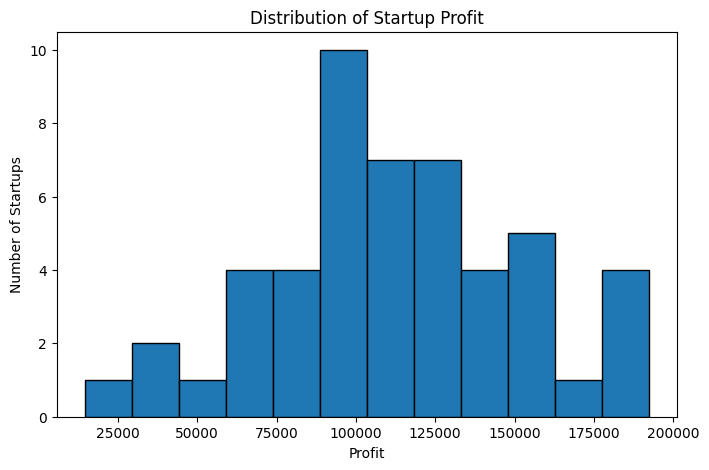

In [8]:
#Histogram
plt.figure(figsize=(8, 5))

plt.hist(df[target].dropna(), bins=12, edgecolor="black")

plt.title("Distribution of Startup Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Startups")

plt.show()

Since profit is the variable I want to predict, I looked at its descriptive statistics and created a histogram to better understand how the values are distributed. The histogram helps me see whether startup profits are concentrated around certain values or spread across a wider range. Understanding the target variable is important before building a regression model.

In [9]:
#Check Correlations
#Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

#Calculate correlations with profit
correlations = numeric_df.corr()[target].sort_values(
    ascending=False
)

print("Correlations with Profit:")
display(correlations)

Correlations with Profit:


Profit             1.000000
R&D Spend          0.972900
Marketing Spend    0.747766
Administration     0.200717
Name: Profit, dtype: float64

I calculated correlations between the numerical variables and profit to see which features may have stronger relationships with the target variable. A positive correlation means the variables tend to increase together, while a negative correlation means one tends to decrease as the other increases. This helps identify potentially useful predictors, although correlation alone does not mean one variable causes another.

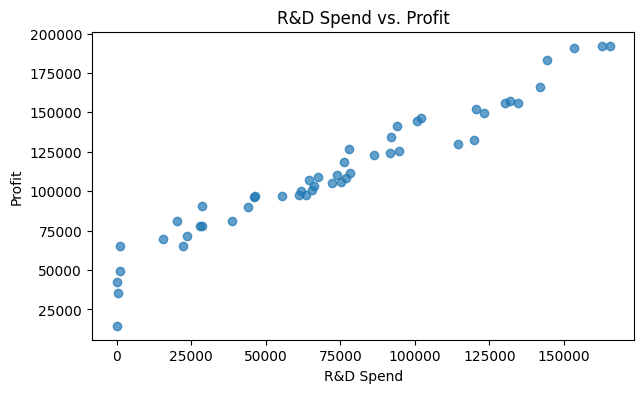

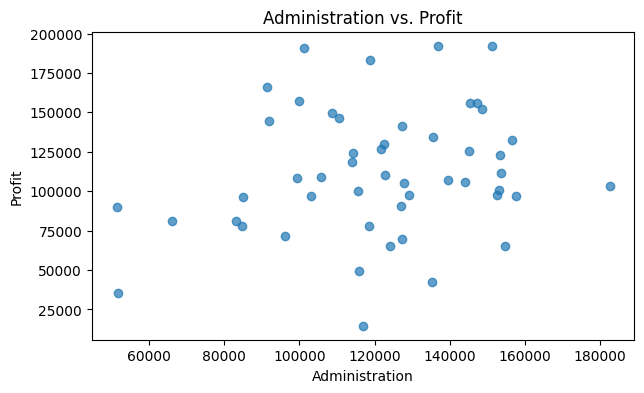

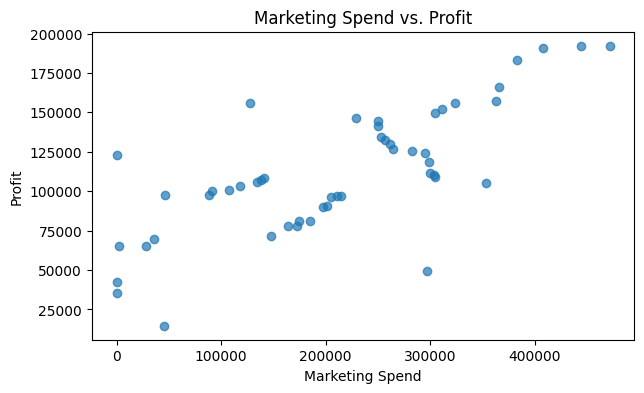

In [10]:
#Visualize with Profit
#Plot numerical predictors against profit
for column in numeric_df.columns:

    if column != target:

        plt.figure(figsize=(7, 4))

        plt.scatter(
            numeric_df[column],
            numeric_df[target],
            alpha=0.7
        )

        plt.title(f"{column} vs. Profit")
        plt.xlabel(column)
        plt.ylabel("Profit")

        plt.show()

I created scatterplots to compare the numerical predictor variables with startup profit. These graphs help me visually identify patterns, possible linear relationships, and outliers that may affect the model. This is another way for me to understand the dataset before moving into feature engineering.

In [11]:
#Separate Predictors and Target
#Create a copy of the dataset
df_clean = df.copy()

#Remove rows with missing target values
df_clean = df_clean.dropna(subset=[target])

In [12]:
#Separate the target and predictors
X = df_clean.drop(columns=[target])
y = df_clean[target]

#Remove empty columns
X = X.dropna(axis=1, how="all")

In [13]:
#Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

print("Predictor Shape:", X.shape)
print("Target Shape:", y.shape)

Numerical Features: ['R&D Spend', 'Administration', 'Marketing Spend']
Categorical Features: ['State']
Predictor Shape: (50, 4)
Target Shape: (50,)


I separated profit from the predictor variables because profit is the target I want the regression model to predict. I also removed any rows where the target value was missing and checked which features were numerical or categorical. This is important because numerical and categorical features need different preparation steps before they can be used in the model.

In [14]:
#Training and Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (40, 4)
Testing Data: (10, 4)


I divided the dataset into training and testing sets, using 80% of the records for training and 20% for testing. The training data will help the model learn relationships between the features and profit. The testing data will be used later to determing how well the model predicts values it has not seen before. I also used random_state=42 so the split can be reproduced.

In [15]:
#Feature Engineering
#Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [16]:
#Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


For feature engineering, I created a preprocessing pipeline that handles numerical and categorical variables separately. Missing numerical values will be filled using the median, and numerical features will be standardized so they are on a similar scale. For categorical variables, missing values will be filled using the most common category, and one-hot encoding will convert those categories into numerical features. Using a pipeline also helps prevent data leakage because the preprocessing steps will be fitted using training data rather than the full dataset.

In [17]:
#Regression Model
#Create Ridge Regression pipeline
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", Ridge(alpha=1.0))
])

#Train the model
model.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


I selected Ridge Regression to predict startup profit. Ridge Regression is similar to Linear Regression, but it includes regularization to help control overly large coefficients. I started with an alpha value of 1.0 as the baseline model. Later on, I plan on testing other alpha values using cross-validation to see whether tuning improves the model. The model was trained using the training dataset.

In [18]:
#Evaluate the Model
#Generate predictions
y_pred = model.predict(X_test)

#Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Baseline Model Evaluation")
print("-------------------------")

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

#Compare actual and predicted profits
results = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": y_pred
})

display(results.head(10))

Baseline Model Evaluation
-------------------------
MAE: 7412.45
RMSE: 9203.48
R² Score: 0.8954


,Actual Profit,Predicted Profit
0,134307.35,126270.281274
1,81005.76,84861.734265
2,99937.59,98095.307856
3,64926.08,46884.898034
4,125370.37,129272.002130
5,35673.41,50050.614701
6,105733.54,108686.130906
7,107404.34,100301.844472
8,97427.84,95871.171475
9,122776.86,110319.483113


After training the model, I used the testing data to generate profit predictions and evaluate its performance. I calculated three regression metrics which give me a baseline to compare against the hyperparameter-tuned model: 
1. MAE measures the average absolute difference between predicted and actual profit. RMSE measures prediction errors while giving more weight to larger mistakes.
2. R^2 measures how much of the variation in profit the model explains compared with predicting the average profit.
3. Lower MAE and RMSE values are better, while a higher R^2 generally indicates a better fit.


In [19]:
#Hyperparameter tuning with cross-validation
#Small set of alpha values to test
param_grid = {
    "regression__alpha": [0.01, 0.1, 1, 10, 100]
}

#Create 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#Hyperparameter tuning
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

In [20]:
#Fit using training data
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation MAE:")
print(round(-grid_search.best_score_, 2))

Best Parameters:
{'regression__alpha': 0.01}
Best Cross-Validation MAE:
7429.48


To improve the model, I used GridSearchCV with 5-fold cross-validation to test different alpha values. Alpha controls how strongly Ridge Regression applies regularization. I tested five values instead of a large number of combinations to keep the process manageable. With 5-fold cross-validation, the training data is divided into five sections. The model trains on four sections and validates on the remaining section, the process repeats until each section has been used for validation. I used MAE to compare the results and identify the alpha value that performed best across the validation folds.

In [21]:
#Review tuning results
#Convert tuning results to a DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

#Display relevant results
tuning_results = cv_results[[
    "param_regression__alpha",
    "mean_test_score",
    "rank_test_score"
]].copy()

In [22]:
#Convert negative MAE into positive MAE
tuning_results["CV MAE"] = -tuning_results["mean_test_score"]

display(
    tuning_results[[
        "param_regression__alpha",
        "CV MAE",
        "rank_test_score"
    ]].sort_values("rank_test_score")
)

,param_regression__alpha,CV MAE,rank_test_score
0,0.01,7429.480210,1
1,0.10,7460.888730,2
2,1.00,7746.471554,3
3,10.00,10335.487845,4
4,100.00,24211.960044,5


I reviewed the cross-validation results to compare the different alpha values. The results show how each alpha value performed based on its average validation MAE. The lowest MAE represents the best performance among the values tested. This helps me understand whether changing the model's hyperparameter improves prediction accuracy.

In [23]:
#Compare original to the tuned models
#Get the best tuned model
best_model = grid_search.best_estimator_

#Generate predictions
tuned_pred = best_model.predict(X_test)

#Calculate tuned metrics
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

#Compare models
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Baseline Model": [mae, rmse, r2],
    "Tuned Model": [tuned_mae, tuned_rmse, tuned_r2]
})

display(comparison)

,Metric,Baseline Model,Tuned Model
0,MAE,7412.447578,6963.037566
1,RMSE,9203.481414,9056.676545
2,R²,0.895400,0.898711


After tuning the model, I evaluated it on the same testing dataset used for the baseline model. I compared MAE, RMSE, and R^2 to see whether hyperparameter tuning improved the predictions. Using the same testing data allows me to compare both models more consistently. The tuned model is not automatically better, so I will use the evaluation results to determine whether the changes improved performance.

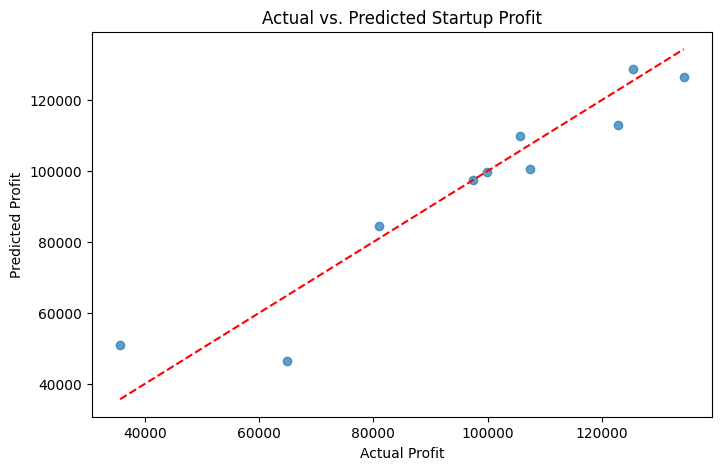

In [24]:
#Visualize final predictions
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    tuned_pred,
    alpha=0.7
)

# Reference line for perfect predictions
minimum = min(y_test.min(), tuned_pred.min())
maximum = max(y_test.max(), tuned_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.title("Actual vs. Predicted Startup Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.show()

I created a scatterplot comparing actual startup profits with the values predicted by the tuned model. The dashed line represents perfect predictions, where the predicted profit would equal the actual profit. Points closer to this line indicate more accurate predictions, while points farther away represent larger prediction errors. This visualization helps me understand the model's performance beyond just the numerical metrics.

In [25]:
#Final Findings and Eval 
print("Baseline Model:")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

print("\nBest Alpha:", grid_search.best_params_["regression__alpha"])

print("\nTuned Model:")
print(f"MAE: {tuned_mae:.2f}")
print(f"RMSE: {tuned_rmse:.2f}")
print(f"R²: {tuned_r2:.4f}")

Baseline Model:
MAE: 7412.45
RMSE: 9203.48
R²: 0.8954

Best Alpha: 0.01

Tuned Model:
MAE: 6963.04
RMSE: 9056.68
R²: 0.8987


To recap, I used the dataset to build a Ridge Regression model to predict startup profits. I started with EDA to explore the data, check for missing values, and identify relationships between variables. I also had to clean the profit column because it wasn't originally being recognized as numerical data. 
After training the model, I evaluated it using MAE, RMSE, and R^2. The baseline model had an MAE of 7,412.45, an RMSE of 9,203.48, and an R^2 of 0.8954, meaning it explained about 89.54% of the variation in profits. After using GridSearchCV with 5-fold cross-validation, the best alpha value was 0.01. The tuned model performed slightly better, with an MAE of 6,963.04, an RMSE of 9,056.68, and an R^2 of 0.8987.

Overall, the model performed pretty well, and tuning helped improve the predictions a little. This exercise helped me understand how important data preparation is and how comparing evaluation metrics can show whether hyperparameter tuning actually makes a difference.